## Assigmet 3 Mideterm 2
### Author: FIlippo Alessandro Sandoval Villarreal

In this assignment, I will implement a Restricted Boltzmann Machine from scratch. The RBM will then be trained on a dataset of images (available at this link: https://huggingface.co/datasets/ylecun/mnist). Following the training, I will use the trained RBM to encode the data from the dataset. These encoded features will then be used to train a new classifier, which will classify the images in the dataset according to their labels.

In [46]:
import pandas as pd
from PIL import Image
import io
import matplotlib.pyplot as plt
import numpy as np
import time
from sklearn import svm
from sklearn.metrics import f1_score
from sklearn.model_selection import ParameterGrid

First, I loaded the provided dataset, which was in parquet format. I used the pandas library to read both the training and test sets.

In [47]:
# i open the parquet file with pandas so i can see the binary nature of the immages

img_bin= pd.read_parquet('train-00000-of-00001.parquet')
img_bin_t= pd.read_parquet('test-00000-of-00001.parquet')
img_bin.head(5)

,image,label
0,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,5
1,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,0
2,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,4
3,"{'bytes': b""\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...",1
4,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,9


The preceding cell prints the first five rows of the training set. As can be seen, the images are represented in byte format, and the corresponding label is an integer in the 'label' column. The test set has the same structure.

In the following cell, I wanted to examine the images in our dataset more closely. First, I wrote a function called *decoding_img* that takes the byte representation of an image and reconstructs it so that it can be viewed as a picture.

In [48]:
def decoding_img (img_byte) :
    try:
        #we are going to decode the image 
        d_im= Image.open(io.BytesIO(img_byte))
        #now we plot an immage
        plt.imshow(d_im)
    except Exception as e:
        print("Error in the image decoding")

In the cell below i show the fourth pictures of the dataset and as we can observe the reconstruction corrispond to its label 

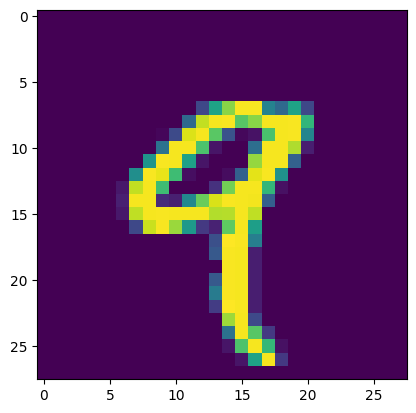

In [49]:
# we take the column that corrispond to the values in bytes of the immage 
img= img_bin['image']

# we show the recostruction for the first image
decoding_img(img[4]['bytes'])


### Data preprocessing

Before implementing the Restricted Boltzmann Machine, I prepared the data for training. This involved encoding the image information into a binary format, starting from the initial byte configuration. Specifically, in the cell below, I defined a function called *Binarize_img*. This function takes the byte configuration of an image, converts it to a grayscale representation (using convert('L')), and then applies a threshold of 0.5 to transform the image from its grayscale format to a binary one.

In [50]:
def Binarize_img (img_bytes, target_size=(28,28), threshold=0.5):
    # i rebuild the image 
    img_r= Image.open(io.BytesIO(img_bytes)).resize(target_size).convert('L')
    img_array= np.array(img_r)/255.0
    binary_img = (img_array>threshold).astype(int)
    return binary_img.flatten()

In the following cell, the *Binarize_img* function is applied to every image in both the training and test sets to obtain their binarized versions. At the end of this cell, the original training set is further split into a training set and a validation set (70% of the data for the training and 30% for the validation). This split is performed to enable model selection across the different Restricted Boltzmann Machine configurations that were explored

In [51]:
from sklearn.model_selection import train_test_split 

input_bin_im = []
test_bin_im = []

for i in range (0,len(img)):
    bin_im = Binarize_img(img[i]['bytes'])
    input_bin_im.append(bin_im)
input_bin_im = np.array(input_bin_im)

img_t= img_bin_t['image']

for i in range (0,len(img_t)):
    bin_im = Binarize_img(img_t[i]['bytes'])
    test_bin_im.append(bin_im)
test_bin_im = np.array(test_bin_im)

# i use sklear for the training and validation set for the training and model selection of the RBM
trainig_set_RBM, validation_set_RBM = train_test_split(input_bin_im,test_size = 0.3, train_size= 0.7, random_state=42)

### Restricted Boltzaman Machine

Following the data preprocessing phase, I implemented a Restricted Boltzmann Machine from scratch. The implementation allows for the selection of several hyperparameters, including the number of hidden units *(K)*, the number of Gibbs sampling steps, the learning rate, the momentum parameter *(β)*, and the regularization strength *(λ)*. The weights are initialized using a Gaussian distribution *N(0,0.01)* of size (visible units × hidden units), and the biases for both the hidden and visible units are initialized randomly with a seed of 3. The implementation consists of the following methods:

**sigmoid**: A simple implementation of the sigmoid function

**forward**: Given a visible input (image), computes the hidden layer's binary activations by computing the hidden unit probabilities: sigmoid(Wᵗ·v + c) and sampling the  binary hidden units using a Bernoulli distribution.

**backward**:Given a binary hidden state, reconstructs the visible layer by computing the visible unit probabilities: sigmoid(W·h + b) and sampling the binary visible units from these probabilities.

**reconstruct**: Performs a forward pass and then reconstructs the input (without binarization). Returns the probabilistic reconstruction (not sampled binary values).

**calculate_reconstruct_error**: this method iterate over the data and use the reconstruct method in order to calculate the reconstruction error over the data using MSE

**train**: contains the logic of the training loop. I used a batch tecniche with batch sixe of 10. In the method there are the update of the weights and biases following the *contrastive_divergence* algorithm.(paper available at this link:(https://www.cs.toronto.edu/~hinton/absps/guideTR.pdf)). To measure the reconstruction error during training, I also calculate the reconstruction error within the training loop.

**energy**:Calculates the energy of a visible-hidden pair following the formula (formula available at this link: https://christian-igel.github.io/paper/TRBMAI.pdf)

**Gibbs_sampling**: Performs Gibbs sampling for K steps, it alternates between sampling hidden and visible units. In particular starts from initial visible state and it returns the final visible and hidden samples after K steps.

**encode**: Encodes a visible vector into hidden probabilities (no sampling). Useful for feature extraction.

The number of the visible unit is 784 because the data from mnist dataset is flattened from a matrix of integers between 0 and 255 to an array of 768 integers. After the flattening binarization is applied with a random threshold generated by a uniform distribution. The reason for the flattening is just to be able to feed it into the rbm while the binarization is useful since it allows the contrastive divergence algorithm to properly work.

In [ ]:
class RBM:
    """This class implements Restricted Boltzman Machin Using Gibbs sampling
       and Contrastive Divergence"""
    
    def __init__(self, n_hidden_layer_size=100, m_observed_inputs=784, K=1, learning_rate = 0.001, beta = 0.9, lamda= 1e-5):
        
        '''Here we do some necessary initialization '''
        
        np.random.seed(3)           ## fixing the random seeds to get consistant results
        
        
        
        self.K = K                     # number of steps in Gibb's chain
        self.learning_rate = learning_rate # will be used in update equation era 25
        
        self.n = n_hidden_layer_size         # our input(visible) and hidder layer size
        self.m = m_observed_inputs
        # m => observed(visible) size
        # n => hidden layer size

        self.weight =  np.random.normal(scale=0.01,size=(self.m,self.n))#np.random.rand(self.m, self.n) * 0.01    # (visible, hidden) 
        self.b = np.random.rand(self.m, 1) * 0.01              # (visble, 1)
        self.c = np.random.rand(self.n, 1) * 0.01              # (hidden, 1)
        
        
        # initializing velocity for momentum term
        self.velocity_w = 0   
        self.velocity_b = 0
        self.velocity_c = 0
        
        
        self.reg_lambda = lamda# constant which controls the regularization 1e-5 era prima
        self.beta = beta     # constant which controls value of momentum era 0.9
        
    # get the sigmoid of given matrix of vector
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
    
    # forward function of Gibb's sampling
    def forward(self, image):
        hidden_distribution = self.sigmoid(self.weight.T @ image + self.c)  # (hidden, 1)
        return np.random.binomial(1, hidden_distribution)                     # (hidden, 1)
    
    
    # backward function for Gibb's sampling
    def backward(self, hidden_representation):
        visible_distribution = self.sigmoid(self.weight @ hidden_representation + self.b)  # [visible, 1]
        return np.random.binomial(1,visible_distribution)                                # [visible, 1]

    def reconstruct(self, visible):
        """Reconstruct the visible units given a visible input."""
        hidden_prob = self.sigmoid(self.weight.T @ visible.reshape(-1, 1) + self.c)
        visible_prob = self.sigmoid(self.weight @ hidden_prob + self.b)
        return visible_prob.flatten()

    def calculate_reconstruction_error(self, data):
        """Calculates the average reconstruction error (MSE) for a dataset."""
        errors = []
        for sample in data:
            reconstructed = self.reconstruct(sample)
            errors.append(((sample - reconstructed) ** 2))
        return np.mean(errors)
     
    # training the RBM using Gibbs sampling and Contrastive divergence
    def train(self, Xtrain, Xval=None, epochs=10, batch_size=32):
        Xtrain = Xtrain.reshape(-1, self.m)
        n_batches = len(Xtrain) // batch_size

        for e in range(epochs):

            self.energy_history = []
            self.reconstruction_error_history = []
            self.val_reconstruction_error_history = []
            start_time = time.time()

            for batch_index in range(n_batches):
                start = batch_index * batch_size
                end = (batch_index + 1) * batch_size
                batch_data = Xtrain[start:end]
                batch_errors = []

                for sample in batch_data:
                    initial_visible = sample.reshape(-1, 1)
                    hidden_original_sample = self.forward(initial_visible)

                    # Running Gibbs chain for K steps
                    visible_sample, hidden_from_gibbs = self.Gibbs_sampling(initial_visible, self.K)

                    # UPDATING THE PARAMETERS USING MOMENTUM AND WEIGHT DECAY

                    # weight update
                    self.velocity_w = self.beta * self.velocity_w + (1-self.beta)* (initial_visible @ hidden_original_sample.T - visible_sample @ hidden_from_gibbs.T)
                    self.weight = (1-self.reg_lambda)* self.weight + self.learning_rate * self.velocity_w

                    # bias 'b' update
                    self.velocity_b = self.beta * self.velocity_b + (1-self.beta)* (initial_visible - visible_sample)
                    self.b += self.learning_rate * self.velocity_b

                    # bias 'c' update
                    self.velocity_c = self.beta * self.velocity_c + (1-self.beta) * (hidden_original_sample - hidden_from_gibbs)
                    self.c += self.learning_rate * self.velocity_c

                    self.energy_history.append(self.energy(initial_visible, hidden_from_gibbs))
                    
                
                self.reconstruction_error_history.append(self.calculate_reconstruction_error(batch_data))

            mean_energy = np.mean(self.energy_history)
            mean_reconstruction_error = np.mean(self.reconstruction_error_history)
            time_taken = time.time() - start_time

            val_error = None
            if Xval is not None:
                val_error = self.calculate_reconstruction_error(Xval)
                self.val_reconstruction_error_history.append(val_error)
                print(f"[Epoch: {e+1}] ==================================")
                print(f"Average Energy: {mean_energy:.3f} | Training Reconstruction Error: {mean_reconstruction_error:.4f} | Validation Reconstruction Error: {val_error:.4f} | Time Taken: {time_taken:.3f} sec")
            else:
                print(f"[Epoch: {e+1}] ==================================")
                print(f"Average Energy: {mean_energy:.3f} | Training Reconstruction Error: {mean_reconstruction_error:.4f} | Time Taken: {time_taken:.3f} sec")

        print("=================== TRAINING ENDED =====================")
    
    
    def energy(self, vis, hidd):
        
        """ Cacluates enegry of the function given visible and hidden samples
        """
        
        term_1 = (vis.T @ self.weight) @ hidd
        term_2 = vis.reshape(1, -1) @ self.b
        term_3 = hidd.reshape(1, -1) @ self.c
        
        energy = -np.squeeze(term_1 + term_2 + term_3)
        
        return energy
    
    
    def Gibbs_sampling(self, initial_visible, K):
        
        '''This functino runs Gibbs chaing for given number of 'K' steps'''
        vt = initial_visible.reshape(-1, 1)
        
        for k in range(K):
            ht = self.forward(vt)
            vt = self.backward(ht)  # (visible, 1)

        return vt, ht

    def encode(self, v):
        """Encode the visible units to hidden unit activations (probabilities)."""
        return self.sigmoid(self.weight.T @ v.reshape(-1, 1) + self.c).flatten()
    

## Restricted Boltzman machine model selection

In the following cell, I performed a grid search over a selection of RBM hyperparameters. Specifically, the search space included two possible numbers of hidden units (100, 200), two different learning rates (0.001, 0.01), two possible values for the regularization parameter λ (1×10−5, 0.5×10 −5), two possible momentum values (β=0.9,0.5), and a fixed number of Gibbs sampling steps (k=1). Due to time constraints, the grid search was limited to these few values; a more comprehensive and fine-grained search could have been conducted.

In [ ]:
from sklearn.model_selection import ParameterGrid

#grid search
grid = ParameterGrid({
    'hidden_units':[100, 200],
    'learning rate': [0.001,0.01],
    'lambda': [1e-5, 0.5e-5],
    'beta': [0.9,0.5],
    'k': [1]
})

validation_recostruction_error= float('inf')
params_best={}

for params in grid:
    # here i print the parameters that i am trying
    print(params)
    #here i declare and create a new RBM
    rbm = rbm_model = RBM(n_hidden_layer_size= params['hidden_units'], m_observed_inputs=784,K=params['k'],learning_rate= params['learning rate'],lamda= params['lambda'], beta= params['beta'])
    # here we start the training
    rbm.train(Xtrain=trainig_set_RBM, Xval=None,batch_size=10)

    # ----- Validation ------
    error_v = rbm.calculate_reconstruction_error(validation_set_RBM)
    print('Validation Loss', error_v)
    # we save the parameters of the best model
    if error_v < validation_recostruction_error:
        validation_recostruction_error = error_v
        params_best = params
        


{'beta': 0.9, 'hidden_units': 100, 'k': 1, 'lambda': 1e-05, 'learning rate': 0.001}
[Epoch: 1] ==================================
Average Energy: 28.326 | Training Reconstruction Error: 0.0794 | Time Taken: 76.526 sec
[Epoch: 2] ==================================
Average Energy: 2.465 | Training Reconstruction Error: 0.0611 | Time Taken: 73.401 sec
[Epoch: 3] ==================================
Average Energy: -8.600 | Training Reconstruction Error: 0.0577 | Time Taken: 74.502 sec
[Epoch: 4] ==================================
Average Energy: -12.451 | Training Reconstruction Error: 0.0566 | Time Taken: 78.442 sec
[Epoch: 5] ==================================
Average Energy: -13.421 | Training Reconstruction Error: 0.0562 | Time Taken: 75.527 sec
[Epoch: 6] ==================================
Average Energy: -14.012 | Training Reconstruction Error: 0.0559 | Time Taken: 80.475 sec
[Epoch: 7] ==================================
Average Energy: -13.993 | Training Reconstruction Error: 0.0559 

The results of the hyperparameter grid search are presented in the cell below. The best performing combination of hyperparameters on the validation set, along with its corresponding validation reconstruction error, is as follows:

Hyperparameter Combination: {'beta': 0.9, 'hidden_units': 200, 'k': 1, 'lambda': 5e-06, 'learning rate': 0.001}
Validation Reconstruction Error: 0.04902201578333977

In [10]:

print(f'the second best comination of parameters: {params_best}, with validation reconstruction error: {validation_recostruction_error}')

the second best comination of parameters: {'beta': 0.9, 'hidden_units': 200, 'k': 1, 'lambda': 5e-06, 'learning rate': 0.001}, with validation reconstruction error: 0.04902201578333977


Following the model selection process, I proceeded to retrain the best-performing RBM configuration using the entire available training dataset.

In [25]:
rbm_best = RBM(n_hidden_layer_size= 200, m_observed_inputs=784,K=1,learning_rate= 0.001,lamda= 0.5e-5, beta= 0.9)
rbm_best.train(input_bin_im, batch_size=10)

[Epoch: 1] ==================================
Average Energy: -11.366 | Training Reconstruction Error: 0.0612 | Time Taken: 279.836 sec
[Epoch: 2] ==================================
Average Energy: -41.040 | Training Reconstruction Error: 0.0497 | Time Taken: 327.276 sec
[Epoch: 3] ==================================
Average Energy: -46.237 | Training Reconstruction Error: 0.0485 | Time Taken: 329.870 sec
[Epoch: 4] ==================================
Average Energy: -46.839 | Training Reconstruction Error: 0.0482 | Time Taken: 334.878 sec
[Epoch: 5] ==================================
Average Energy: -46.019 | Training Reconstruction Error: 0.0483 | Time Taken: 330.302 sec
[Epoch: 6] ==================================
Average Energy: -44.523 | Training Reconstruction Error: 0.0486 | Time Taken: 330.238 sec
[Epoch: 7] ==================================
Average Energy: -43.840 | Training Reconstruction Error: 0.0489 | Time Taken: 331.433 sec
[Epoch: 8] ==================================
Av

## Same RBM but different k

As specified by the assignment guidelines, I also conducted an experiment training the same RBM architecture but with a different number of Gibbs sampling steps, specifically k=5. Initially, I trained this new RBM configuration and evaluated its performance on the validation set. The results obtained from this training and evaluation are visualized in the cell below.

In [11]:
rbm_best_k = RBM(n_hidden_layer_size= 200, m_observed_inputs=784,K=5,learning_rate= 0.001,lamda= 0.5e-5, beta= 0.9)
rbm_best_k.train(trainig_set_RBM, batch_size=10)
validation = rbm_best_k.calculate_reconstruction_error(validation_set_RBM)
print('validation error with k = 5 is',validation)

[Epoch: 1] ==================================
Average Energy: -75.619 | Training Reconstruction Error: 0.0474 | Time Taken: 189.642 sec
[Epoch: 2] ==================================
Average Energy: -144.301 | Training Reconstruction Error: 0.0317 | Time Taken: 201.282 sec
[Epoch: 3] ==================================
Average Energy: -176.229 | Training Reconstruction Error: 0.0274 | Time Taken: 202.656 sec
[Epoch: 4] ==================================
Average Energy: -199.552 | Training Reconstruction Error: 0.0250 | Time Taken: 202.238 sec
[Epoch: 5] ==================================
Average Energy: -218.286 | Training Reconstruction Error: 0.0234 | Time Taken: 201.817 sec
[Epoch: 6] ==================================
Average Energy: -237.844 | Training Reconstruction Error: 0.0222 | Time Taken: 201.339 sec
[Epoch: 7] ==================================
Average Energy: -254.894 | Training Reconstruction Error: 0.0213 | Time Taken: 201.267 sec
[Epoch: 8] ===============================

As can be observed, the training of the RBM with k=5 Gibbs sampling steps appears more stable and yields a lower reconstruction error compared to the RBM trained with k=1.

Similar to the procedure with the k=1 RBM, I then decided to retrain the k=5 RBM using the entire available training dataset.

In [12]:
rbm_best_k =RBM(n_hidden_layer_size= 200, m_observed_inputs=784,K=5,learning_rate= 0.001,lamda= 0.5e-5, beta= 0.9)
rbm_best_k.train(input_bin_im, batch_size=10)

[Epoch: 1] ==================================
Average Energy: -92.986 | Training Reconstruction Error: 0.0430 | Time Taken: 274.629 sec
[Epoch: 2] ==================================
Average Energy: -164.954 | Training Reconstruction Error: 0.0287 | Time Taken: 293.724 sec
[Epoch: 3] ==================================
Average Energy: -198.471 | Training Reconstruction Error: 0.0250 | Time Taken: 290.711 sec
[Epoch: 4] ==================================
Average Energy: -224.401 | Training Reconstruction Error: 0.0229 | Time Taken: 288.937 sec
[Epoch: 5] ==================================
Average Energy: -248.234 | Training Reconstruction Error: 0.0215 | Time Taken: 288.312 sec
[Epoch: 6] ==================================
Average Energy: -269.047 | Training Reconstruction Error: 0.0205 | Time Taken: 288.378 sec
[Epoch: 7] ==================================
Average Energy: -286.829 | Training Reconstruction Error: 0.0198 | Time Taken: 287.339 sec
[Epoch: 8] ===============================

## Econding of the data and training of the new classifier with the RBM and k=5

Once both RBM models were trained, I proceeded to encode the data from the training and test sets. This was done to generate features that could be used to train and evaluate a new classifier. Specifically, I implemented two separate loops, where in each loop, the encode method of the respective trained RBM was applied to all data points in the training and test sets.

In [54]:
xtrain = []

for img in input_bin_im:
    enc=rbm_best_k.encode(img)
    xtrain.append(enc)
xtrain = np.array(xtrain)

# now for the test set
X_test = []

for img in test_bin_im:
    enc=rbm_best_k.encode(img)
    X_test.append(enc)
X_test = np.array(X_test)


After encoding the data using the RBM trained with k=5 Gibbs sampling steps, I chose to use a Support Vector Classifier (SVC) to classify the images in our dataset. I selected the Support Vector Classifier (SVC) due to its suitability for this type of image classification task, as highlighted on the scikit-learn documentation page (https://scikit-learn.org/stable/auto_examples/classification/plot_digits_classification.html), where an SVC was used for a similar problem.

I began by splitting the encoded training data into training and validation sets to perform model selection over the SVC's hyperparameters. The hyperparameters tuned were: the regularization parameter C (with values 0.1, 1, and 10), the kernel type (linear, sigmoid, and poly), the kernel coefficient gamma (fixed at 0.001, as suggested in the linked documentation (https://scikit-learn.org/stable/auto_examples/classification/plot_digits_classification.html)), and the degree of the polynomial kernel (with values 2 and 3; this parameter is only relevant for the 'poly' kernel and ignored by others). The evaluation metric used for model selection was the micro-averaged F1 score.

As with the RBM hyperparameter tuning, I acknowledge that the limited time available constrained the depth of this grid search. A more extensive exploration of the hyperparameter space could potentially have yielded even better performance.

In [ ]:

Xtrain = xtrain
Ytrain = img_bin['label']

#dati ed labels di validation
X_train,X_validation,y_train,y_validation = train_test_split(Xtrain,Ytrain,test_size=0.3,random_state=42,stratify=Ytrain)

#dati e labels per il testing
xtest = X_test
ytest = img_bin_t['label']

#grid search for the svc
grid = ParameterGrid({
    'kernel' : ['linear','poly','sigmoid'],
    'C' : [1,0.1,10],
    'gamma' : [0.001],
    'degree' : [2,3]
})

#starting of the model selection
best_params=[]
best_f1= float('-inf')

for params in grid:
    
    print('proviamo questi parametri adesso', params)
    
    # Here i declare the model 
    model = svm.SVC(**params)
    
    #starting del training
    model.fit(Xtrain,Ytrain)
    
    # validation predictions
    y_pred = model.predict(X_validation)
    
    # calculate the F1 sccore in order to evaluate the model 
    F1_score = f1_score(y_validation, y_pred, average='micro')
    
    print( f'the logistic regression with parameters {params} obtained a f1 score of {F1_score}')
    
    if F1_score > best_f1:
        # choosing the best F1 score
        best_f1 = F1_score
        best_params=params


print(f'the best model obtains a F1 score of {best_f1} with params {best_params}')


proviamo questi parametri adesso {'C': 1, 'degree': 2, 'gamma': 0.001, 'kernel': 'linear'}
the logistic regression with parameters {'C': 1, 'degree': 2, 'gamma': 0.001, 'kernel': 'linear'} obtained a f1 score of 0.9715555555555555
proviamo questi parametri adesso {'C': 1, 'degree': 2, 'gamma': 0.001, 'kernel': 'poly'}
the logistic regression with parameters {'C': 1, 'degree': 2, 'gamma': 0.001, 'kernel': 'poly'} obtained a f1 score of 0.9119444444444444
proviamo questi parametri adesso {'C': 1, 'degree': 2, 'gamma': 0.001, 'kernel': 'sigmoid'}
the logistic regression with parameters {'C': 1, 'degree': 2, 'gamma': 0.001, 'kernel': 'sigmoid'} obtained a f1 score of 0.9318888888888889
proviamo questi parametri adesso {'C': 1, 'degree': 3, 'gamma': 0.001, 'kernel': 'linear'}
the logistic regression with parameters {'C': 1, 'degree': 3, 'gamma': 0.001, 'kernel': 'linear'} obtained a f1 score of 0.9715555555555555
proviamo questi parametri adesso {'C': 1, 'degree': 3, 'gamma': 0.001, 'kernel

The best-performing Support Vector Classifier achieved a micro-averaged F1 score of 0.9758333333333333 on the validation set with the following hyperparameters: {'C': 10, 'degree': 2, 'gamma': 0.001, 'kernel': 'linear'}. The result of this model selection is printed in the cell below.

In [23]:
print(f'the best model obtains a F1 score of {best_f1} with params {best_params}')

the best model obtains a F1 score of 0.9758333333333333 with params {'C': 10, 'degree': 2, 'gamma': 0.001, 'kernel': 'linear'}


## Econding of the data and training of the new classifier with the RBM and k=5

In this section, I repeated the same steps as performed for the RBM with k=5, but this time using the RBM trained with k=1 Gibbs sampling step. This involved first encoding the training and test datasets using the encode method of the k=1 RBM. Following the encoding, I proceeded with the hyperparameter selection for the Support Vector Classifier using the same grid search strategy as before.

In [53]:
xtrain_1 = []

for img in input_bin_im:
    enc=rbm_best.encode(img)
    xtrain_1.append(enc)
xtrain_1 = np.array(xtrain_1)

# now for the test set
X_test_1 = []

for img in test_bin_im:
    enc=rbm_best.encode(img)
    X_test_1.append(enc)
X_test_1 = np.array(X_test_1)


The hyperparameter selection for the SVC using the features encoded by the k=1 RBM followed the same grid search strategy as before, with one key difference: I excluded the polynomial kernel from the search space. This decision was based on the observation that the polynomial kernel yielded inferior performance compared to the linear and sigmoid kernels in the previous model selection process using the features from the k=5 RBM.

In [ ]:
Xtrain_1 = xtrain_1
Ytrain_1 = img_bin['label']

#dati ed labels di validation
X_train_1,X_validation_1,y_train_1,y_validation_1 = train_test_split(Xtrain_1,Ytrain_1,test_size=0.3,random_state=42,stratify=Ytrain_1)

#dati e labels per il testing
xtest_1 = X_test_1
ytest_1 = img_bin_t['label']

#Grid search fot the svc
grid_1 = ParameterGrid({
    'kernel' : ['linear','sigmoid'],
    'C' : [1,0.1,10],
    'gamma' : [0.001],##not used
    'degree' : [2,3]
})

# stariting of the model selction 
best_params_1=[]
best_f1_1= float('-inf')

for params in grid_1:
    
    print('proviamo questi parametri adesso', params)
    
    # Here i declare the model 
    model = svm.SVC(**params)
    
    #starting del training
    model.fit(Xtrain_1,Ytrain_1)
    
    # validation predictions
    y_pred = model.predict(X_validation_1)
    
    # calculate the F1 sccore in order to evaluate the model 
    F1_score = f1_score(y_validation_1, y_pred, average='micro')
    
    print( f'the logistic regression with parameters {params} obtained a f1 score of {F1_score}')
    
    if F1_score > best_f1_1:
        # choosing the best F1 score
        best_f1_1 = F1_score
        best_params_1 = params


print(f'the best model obtains a F1 score of {best_f1_1} with params {best_params_1}')


proviamo questi parametri adesso {'C': 1, 'degree': 2, 'gamma': 0.001, 'kernel': 'linear'}
the logistic regression with parameters {'C': 1, 'degree': 2, 'gamma': 0.001, 'kernel': 'linear'} obtained a f1 score of 0.8811666666666667
proviamo questi parametri adesso {'C': 1, 'degree': 2, 'gamma': 0.001, 'kernel': 'sigmoid'}
the logistic regression with parameters {'C': 1, 'degree': 2, 'gamma': 0.001, 'kernel': 'sigmoid'} obtained a f1 score of 0.8263333333333334
proviamo questi parametri adesso {'C': 1, 'degree': 3, 'gamma': 0.001, 'kernel': 'linear'}
the logistic regression with parameters {'C': 1, 'degree': 3, 'gamma': 0.001, 'kernel': 'linear'} obtained a f1 score of 0.8811666666666667
proviamo questi parametri adesso {'C': 1, 'degree': 3, 'gamma': 0.001, 'kernel': 'sigmoid'}
the logistic regression with parameters {'C': 1, 'degree': 3, 'gamma': 0.001, 'kernel': 'sigmoid'} obtained a f1 score of 0.8263333333333334
proviamo questi parametri adesso {'C': 0.1, 'degree': 2, 'gamma': 0.001,

The best-performing Support Vector Classifier, when trained on the features encoded by the RBM with k=1 Gibbs sampling step, achieved a micro-averaged F1 score of 0.8877777777777778 on the validation set. The optimal hyperparameters found were: {'C': 10, 'degree': 2, 'gamma': 0.001, 'kernel': 'linear'}. The result of this model selection is printed in the cell below.

In [28]:
print(f'the best model obtains a F1 score of {best_f1_1} with params {best_params_1}')

the best model obtains a F1 score of 0.8877777777777778 with params {'C': 10, 'degree': 2, 'gamma': 0.001, 'kernel': 'linear'}


## Retraining and test of the two SVC

After completing the model selection for the SVC using the two different encodings of the data (from the k=1 and k=5 RBMs), I proceeded to retrain the best-performing SVC model for each encoding. This retraining was done using the entire training dataset. Following this, I evaluated the performance of both retrained SVC models on the held-out test set.

In the cell below, I retrained the Support Vector Classifier using the entire training dataset that was previously encoded by the Restricted Boltzmann Machine with k=1 Gibbs sampling step.

In [29]:
svm_k_1 = svm.SVC(C=10,degree=2,gamma=0.001,kernel='linear')
svm_k_1.fit(Xtrain_1,Ytrain_1)

SVC(C=10, degree=2, gamma=0.001, kernel='linear')

In the cell below, I retrained the Support Vector Classifier using the entire training dataset that was previously encoded by the Restricted Boltzmann Machine with k=5 Gibbs sampling steps.

In [30]:
svm_k_5 = svm.SVC(C=10,degree=2,gamma=0.001,kernel='linear')
svm_k_5.fit(Xtrain,Ytrain)

SVC(C=10, degree=2, gamma=0.001, kernel='linear')

After retraining the best SVC models (one for each RBM encoding) on the full training dataset, I evaluated their performance on the test set. This involved using the test set that had been encoded by each of the two different RBM models (k=1 and k=5). Finally, I printed the micro-averaged F1 score obtained by each SVC model on the respective encoded test set, using the same evaluation metric as during the validation phase.

In [57]:
test_pred = svm_k_1.predict(X_test_1) #mettiamo il traning 1 boltzman
test_pred2 = svm_k_5.predict(X_test) #mettiamo il traning 2 boltzman

test_f1_k_1 = f1_score(ytest_1, test_pred,average='micro')
test_f1_k_5 = f1_score(ytest, test_pred2,average='micro')

print(f'the f1 score obtained in test was of the {test_f1_k_1}')
print(f'the f1 score obtained in test was of the {test_f1_k_5}')


the f1 score obtained in test was of the 0.8836
the f1 score obtained in test was of the 0.9469


### Conclusions

As the results from the two Support Vector Classifiers demonstrate, the one trained on the features encoded by the RBM with k=5 Gibbs sampling steps performed significantly better, achieving a higher F1 score on both the validation set (0.975) and the test set (0.946).

This performance difference aligns with the observed reconstruction errors of the two RBMs. The RBM with k=1 exhibited a validation reconstruction error of 0.049, whereas the RBM with k=5 showed a considerably lower reconstruction error of 0.019. As explained in this article (available at this link: https://medium.com/@heyamit10/gibbs-sampling-for-training-rbms-0021a59c876d), the number of Gibbs sampling steps (k) plays a crucial role. A higher number of steps allows the model to better capture the underlying features of the images and more accurately approximate the gradient of the log-likelihood. While the initial Gibbs samples might not be optimal, later steps tend to provide a better representation of the data distribution. Consequently, a larger k value helps the RBM learn more meaningful features, leading to better image reconstruction.

This improved gradient approximation during the training of the k=5 RBM likely contributed to a more stable learning process with fewer erratic weight and bias updates. This stability was indeed reflected in the training curves, where the k=5 RBM showed less oscillation in its reconstruction error compared to the k=1 RBM.

The superior feature representation learned by the k=5 RBM directly impacted the classification performance of the subsequent SVC. When images are passed through the RBM for encoding, some information loss is inevitable. However, an RBM that can capture the most salient features more effectively will produce a more informative encoding. This more precise encoding then allows the SVC to learn a better decision boundary, resulting in higher classification f1 score on both the validation and test sets.


